In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth_data = os.path.join('..', 'data')
pth_in = os.path.join(pth_data, 'cancer', 'human', 'CCCA')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
# pth_out = os.path.join(pth_data, 'results', 'cancer', 'CCCA')
# pth_fig = os.path.join(pth, 'figures', 'cancer', 'human', 'CCCA')

In [5]:
adata_cancer = sc.read_h5ad(os.path.join(pth_in, 'malignant.h5ad'))
adata_cancer.X = np.asarray(adata_cancer.X.toarray() - 
                            adata_cancer.X.mean(axis = 1))
adata_cancer

AnnData object with n_obs × n_vars = 1406087 × 245
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [6]:
adata_normal = sc.read_h5ad(os.path.join(pth_in, 'normal.h5ad'))
adata_normal.X = np.asarray(adata_normal.X.toarray() - 
                            adata_normal.X.mean(axis = 1))
adata_normal

AnnData object with n_obs × n_vars = 3494948 × 245
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [3]:
# select genes: pSom | Crest
get_feat = lambda pth: pd.read_csv(pth).hsapiens.drop_duplicates()
g1 = get_feat(os.path.join(pth_feat, 'GSE229103.csv'))
g2 = get_feat(os.path.join(pth_feat, 'rRNAModifications.csv'))
g = pd.merge(g1, g2, 'outer').hsapiens

In [13]:
X_cancer = pd.DataFrame(adata_cancer[:, g].X.toarray(),
                        index = adata_cancer.obs_names,
                        columns = g)
adata_cancer.obs = adata_cancer.obs.join(X_cancer)

In [14]:
X_normal = pd.DataFrame(adata_normal[:, g].X.toarray(),
                        index = adata_normal.obs_names,
                        columns = g)
adata_normal.obs = adata_normal.obs.join(X_normal)

In [19]:
by = ['sample', 'source', 'Disease']
df_cancer = (adata_cancer.obs
             .groupby(by, observed = True)
             [g].mean()
             .groupby(by[-1], observed = True)
             .mean()
             .mean())
df_cancer

GRSF1       0.297339
LRIG3      -0.201640
MEIS2      -0.058868
RUVBL2      0.387569
ACTN1       0.121628
              ...   
SLC2A1      0.057728
STAMBPL1   -0.223771
LRRC58      0.277337
EEF1D       1.675386
TBXT       -0.374855
Length: 188, dtype: float64

In [20]:
by = ['sample', 'source', 'Disease']
df_normal = (adata_normal.obs
             .groupby(by, observed = True)
             [g].mean()
             .groupby(by[-1], observed = True)
             .mean()
             .mean())
df_normal

GRSF1       0.198330
LRIG3      -0.186928
MEIS2      -0.149824
RUVBL2      0.101891
ACTN1       0.054178
              ...   
SLC2A1     -0.002650
STAMBPL1   -0.066620
LRRC58      0.176439
EEF1D       1.837436
TBXT       -0.261550
Length: 188, dtype: float64

In [ ]:
# # compute gene-module correlations
# X = pd.DataFrame(adata_plt.X.toarray(),
#                  index = adata_plt.obs_names,
#                  columns = adata.var_names)
# X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
# R = pd.DataFrame(index = X.columns)
# mod1 = adata_plt.obs.GSE162534.values[:, None]
# mod2 = adata_plt.obs.GSE229103.values[:, None]
# R['Gast'] = pearsonr(X, mod1, axis = 0).statistic
# R['pSom'] = pearsonr(X, mod2, axis = 0).statistic
# rank = R.abs().sum(axis = 1).rank(ascending = False)
# R = R.loc[rank.sort_values().index].copy()

# # module labels
# msk_dict = {
#     'Gast' : R.index.isin(g1) & ~R.index.isin(g2),
#     'pSom' : ~R.index.isin(g1) & R.index.isin(g2),
#     'Both' : R.index.isin(g1) & R.index.isin(g2)}
# for mod, msk in msk_dict.items():
#     R.loc[msk, 'Module'] = mod
#     print(mod, msk.sum())
# R['Module'] = pd.Categorical(R.Module,
#                              reversed(msk_dict.keys()),
#                              ordered = True)

In [ ]:
# # plot correlations
# fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
# for mod, sdf in R.groupby('Module', observed = True):
#     sdf.plot(kind = 'scatter', x = 'Gast', y = 'pSom',
#              color = c_dict[mod], label = mod, s = 25,
#              alpha = .6, linewidth = 0, ax = ax)
# ax.axvline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
# ax.axhline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
# xlim = abs(np.asarray(ax.get_xlim())).max()
# ylim = abs(np.asarray(ax.get_ylim())).max()
# ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)

# # label top genes
# texts = list()
# for ix in R.head(15).index:
#     texts.append(ax.text(
#         R.loc[ix].Gast,
#         R.loc[ix].pSom,
#         ix, fontsize = 6.75,
#         fontstyle = 'italic'))
# adjust_text(texts = texts)

# leg = ax.legend(title = 'Module',
#                 title_fontsize = 7.5,
#                 handlelength = 1,
#                 handletextpad = .5,
#                 borderaxespad = .65,
#                 fontsize = 7.5,
#                 reverse = True)

# # mutual correlation
# ax.text(.99, .01, r'$r=$' + f'{rval}',
#         transform = ax.transAxes,
#         fontsize = 10, color = 'tab:red',
#         ha = 'right', va = 'bottom')

# ax.set_title('Early Epiblast')
# ax.set_xlabel(r'Gast Correlation ($r$)')
# ax.set_ylabel(r'pSom Correlation ($r$)')
# fn = os.path.join(pth_out, 'Epi_early.pdf')
# plt.savefig(fn, bbox_inches = 'tight')

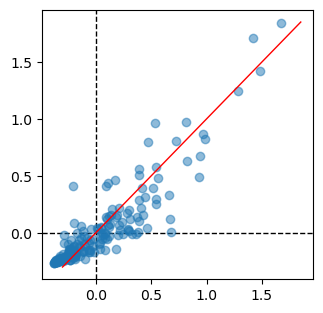

In [ ]:
plt.figure(figsize = (2.5, 2.5))
plt.scatter(df_cancer, df_normal, alpha = .5)
plt.plot([-.3, 1.85], [-.3, 1.85], c = 'r', lw = 1)
plt.axvline(0, c = 'k', lw = 1, ls = '--', zorder = 0)
plt.axhline(0, c = 'k', lw = 1, ls = '--', zorder = 0)
plt.show()

In [51]:
ix = ((df_cancer - df_normal)
      .sort_values(ascending = False))
print(df_cancer.loc[ix.head(10).index],
      '\n\n',
      df_normal.loc[ix.head(10).index])

TUBB2B     0.677633
MAGED1     0.669222
NHP2       0.927868
CCND1      0.461774
LAPTM4B    0.363203
MEST       0.382403
APP        0.664754
UCHL1      0.326294
PYCR1      0.182158
SPINT2     0.539950
dtype: float64 

 TUBB2B     0.005045
MAGED1     0.118499
NHP2       0.486939
CCND1      0.041130
LAPTM4B   -0.008012
MEST       0.011740
APP        0.328792
UCHL1     -0.006478
PYCR1     -0.138452
SPINT2     0.252596
dtype: float64
